In [1]:
pip install pandas==2.2.3

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 4.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 6.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.4/16.4 MB 6.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 347.8/347.8 kB 6.1 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install matplotlib==3.10.0

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.5/102.5 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 6.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 326.2/326.2 kB 6.1 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 6.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 6.2 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 6.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.1/111.1 kB 5.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install seaborn==0.13.2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 5.6 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd

from IPython.display import display, HTML
display(HTML("<style>.container { width:1000% !important; }</style>"))
pd.options.display.max_columns=400
pd.options.display.max_rows=8000

import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df_outages = pd.read_csv("data/outage_report_summaries.csv")
df_services = pd.read_csv("data/cloud_service_risk_ratings.csv")
# Filter first dummy record of file
df_services = df_services[df_services['service_provider'].str.contains('BAD CLOUD EXAMPLE') == False]

In [6]:
#df_outages

In [7]:
#df_services

In [8]:
df_outages1 = df_outages[df_outages['cloud_provider'].str.contains('AWS|GCP|Azure|MongoDB|IBM|Oracle') == False] # Exclude to view  not in != Oracle 
df_outages1

,outage_timestamp,source_outage_report,cloud_provider,cloud_service,regions,availability_zones,start_time,end_time,outage_status,impact,duration,duration_minutes,root_cause,resolution,downtime_period,incident_id,affected_components,mitigation_steps,cloudrisk_genai_output


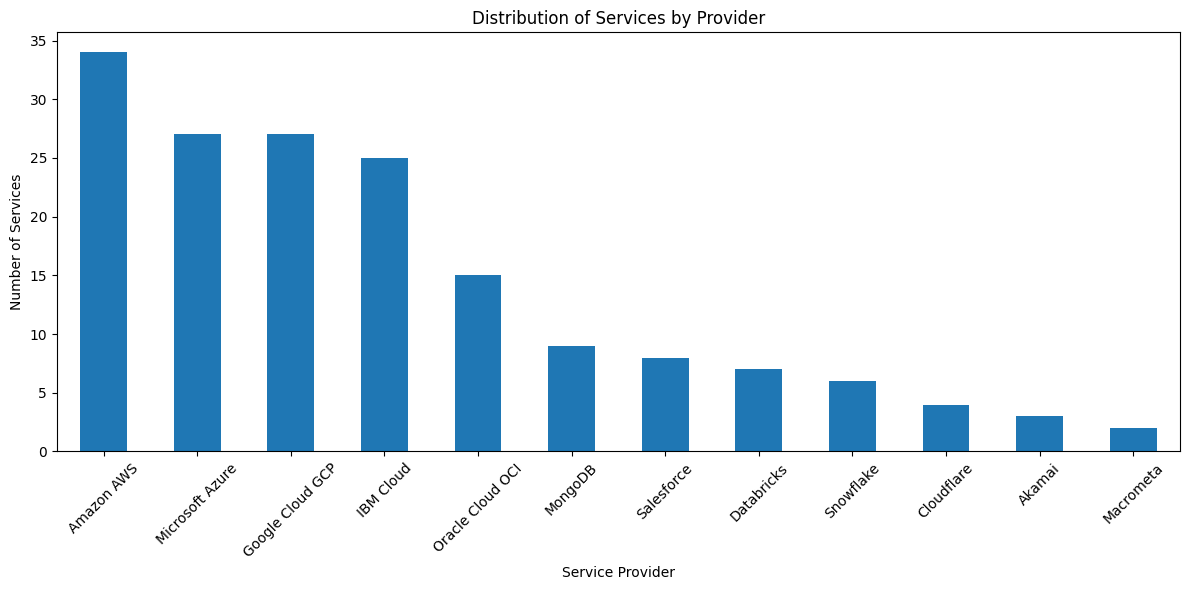

In [9]:
# 1.Service Provider Distribution:
df = df_services
plt.figure(figsize=(12, 6))
df['service_provider'].value_counts().plot(kind='bar')
plt.title('Distribution of Services by Provider')
plt.xlabel('Service Provider')
plt.ylabel('Number of Services')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

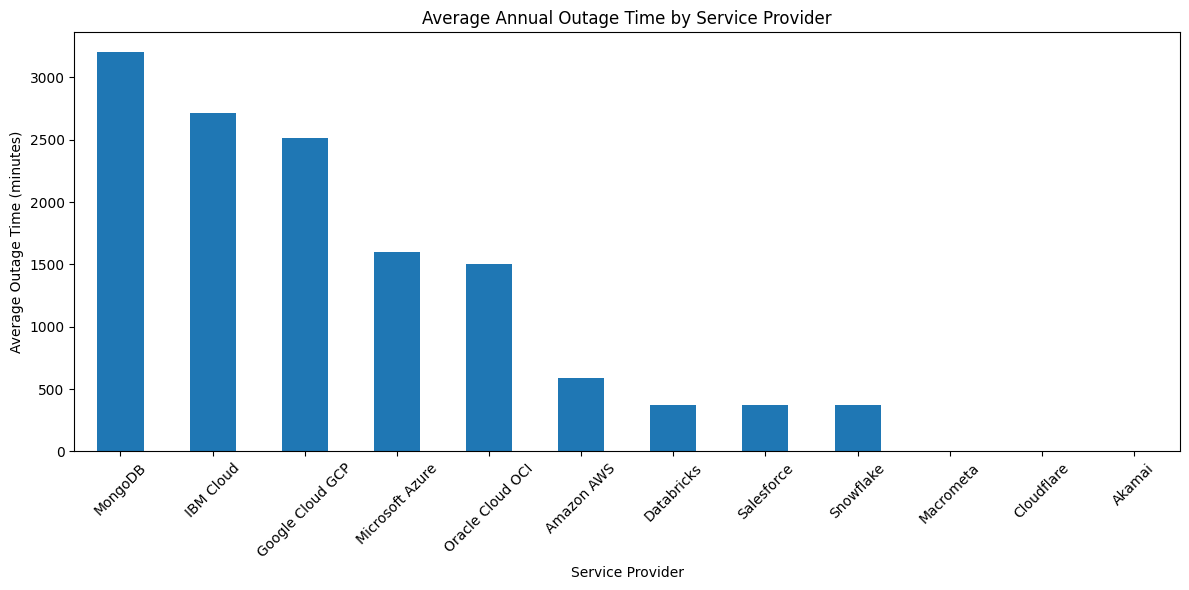

In [10]:
# 2.Average Annual Outage Time by Service Provider:
plt.figure(figsize=(12, 6))
df.groupby('service_provider')['webscraper_annual_period_service_down_per_year_in_minutes'].mean().sort_values(ascending=False).plot(kind='bar')
plt.title('Average Annual Outage Time by Service Provider')
plt.xlabel('Service Provider')
plt.ylabel('Average Outage Time (minutes)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

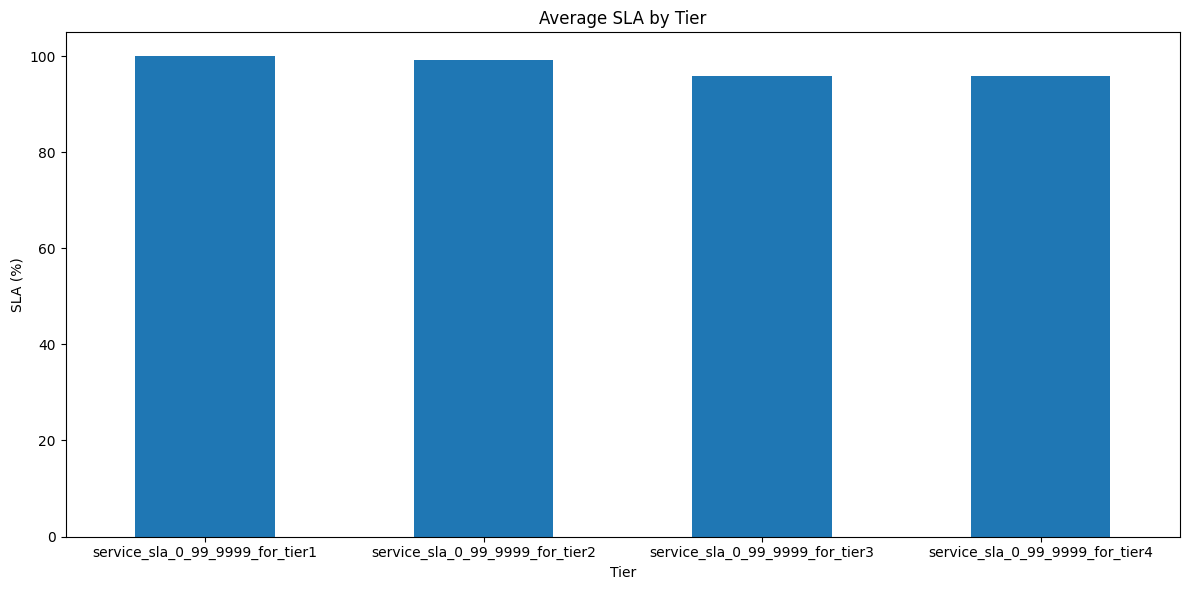

In [11]:
# 3.Service SLA Tiers Comparison:
plt.figure(figsize=(12, 6))
df[['service_sla_0_99_9999_for_tier1', 'service_sla_0_99_9999_for_tier2', 'service_sla_0_99_9999_for_tier3', 'service_sla_0_99_9999_for_tier4']].mean().plot(kind='bar')
plt.title('Average SLA by Tier')
plt.xlabel('Tier')
plt.ylabel('SLA (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

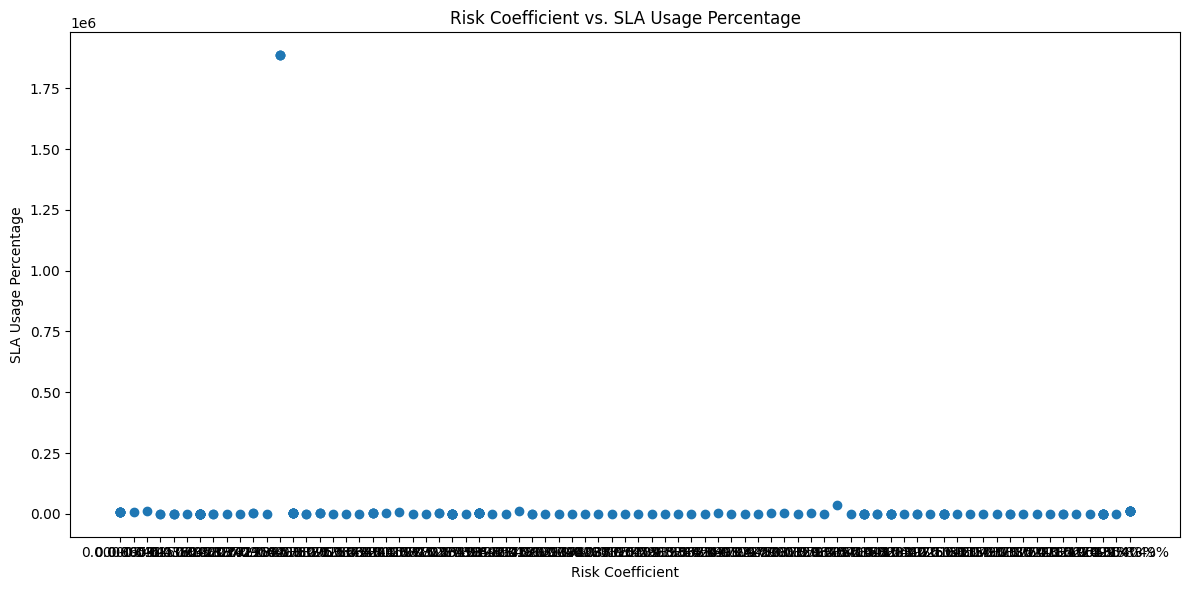

In [12]:
# 4.Risk Coefficient vs. SLA Usage Percentage:
plt.figure(figsize=(12, 6))
plt.scatter(df['riskcoef_per_service_from_gap_expected_actual_time_down'], df['service_sla_usage_percentage'])
plt.title('Risk Coefficient vs. SLA Usage Percentage')
plt.xlabel('Risk Coefficient')
plt.ylabel('SLA Usage Percentage')
plt.tight_layout()
plt.show()

In [13]:
# Global
df_outages_dedup = df_outages.drop_duplicates(subset=['outage_timestamp','source_outage_report','cloud_provider','cloud_service','regions']).sort_values(by=['outage_timestamp'],ascending=True)
df_outages_dedup ['duration_minutes'] = df_outages_dedup ['duration_minutes'].apply(lambda x: round(x, 2))
df_outages_dedup.to_csv('data/new_sorted_outages_dedup.csv', index=False)

# For Cloud Services - Insert Calculus to- webscraper_annual_period_service_down_per_year_in_minutes 
df_order_cloud_services_time = df_outages_dedup.sort_values(by=['cloud_provider','cloud_service','regions','outage_timestamp'],ascending=True)
df_order_cloud_services_time .to_csv('data/df_order_cloud_services_time.csv', index=False)


In [14]:
df_outages_dedup.describe()

,outage_timestamp,duration_minutes,resolution,mitigation_steps
count,6.398000e+03,6398.000000,0.0,0.0
mean,1.693889e+09,6341.915442,NaN,NaN
std,5.169987e+07,53409.047033,NaN,NaN
min,1.576085e+09,0.000000,NaN,NaN
25%,1.648725e+09,103.000000,NaN,NaN
50%,1.723581e+09,331.000000,NaN,NaN
75%,1.731225e+09,460.000000,NaN,NaN
max,1.744457e+09,563040.000000,NaN,NaN


In [15]:
df_outages_dedup.shape[0]

6398

In [16]:
df_outages_dedup.head(5)

,outage_timestamp,source_outage_report,cloud_provider,cloud_service,regions,availability_zones,start_time,end_time,outage_status,impact,duration,duration_minutes,root_cause,resolution,downtime_period,incident_id,affected_components,mitigation_steps,cloudrisk_genai_output
1106,1.576085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure CDN,north america,not specified,2019-12-11T17:24:00+00:00,2019-12-11T21:48:00+00:00,resolved,NaN,4 hours and 24 minutes,264,Staged deployment process,NaN,"17:24-21:48 UTC on December 11, 2019",NaN,Azure CDN,NaN,Source Outage Report: outages_files/Azure_stat...
1107,1.576085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,global (except north america),not specified,2019-12-11T17:24:00+00:00,2019-12-11T21:48:00+00:00,resolved,NaN,4 hours and 24 minutes,264,Staged deployment process,NaN,"17:24-21:48 UTC on December 11, 2019",NaN,Azure CDN,NaN,Source Outage Report: outages_files/Azure_stat...
1108,1.576085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,north america,not specified,2019-12-11T17:24:00+00:00,2019-12-11T21:48:00+00:00,resolved,NaN,4 hours and 24 minutes,264,Staged deployment process,NaN,"17:24-21:48 UTC on December 11, 2019",NaN,Azure CDN,NaN,Source Outage Report: outages_files/Azure_stat...
1105,1.576085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure CDN,global (except north america),not specified,2019-12-11T17:24:00+00:00,2019-12-11T21:48:00+00:00,resolved,NaN,4 hours and 24 minutes,264,Staged deployment process,NaN,"17:24-21:48 UTC on December 11, 2019",NaN,Azure CDN,NaN,Source Outage Report: outages_files/Azure_stat...
979,1.582894e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Ams,eastasia,not specified,2020-02-28T12:48:00+00:00,2020-02-28T22:28:00+00:00,investigating,NaN,6 hours and 22 minutes,382,Incorrect configuration change,NaN,19:10 - 22:28 UTC (3 hours and 18 minutes),NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...


In [17]:
df_outages_dedup.tail(5)

,outage_timestamp,source_outage_report,cloud_provider,cloud_service,regions,availability_zones,start_time,end_time,outage_status,impact,duration,duration_minutes,root_cause,resolution,downtime_period,incident_id,affected_components,mitigation_steps,cloudrisk_genai_output
2972,1.743253e+09,outages_files/Google Cloud Service Health - 29...,GCP,AlloyDB for PostgreSQL,us-east5-c,not specified,2025-03-29T12:53:00+00:00,2025-03-30T19:12:00+00:00,resolved,NaN,6 hours and 19 minutes,379,Utility power outage in the zone and failure o...,NaN,"March 29, 2025, 12:53 UTC - March 30, 2025, 19...",NaN,NaN,NaN,Source Outage Report: outages_files/Google Clo...
2973,1.743253e+09,outages_files/Google Cloud Service Health - 29...,GCP,Google Cloud Bigtable,us-east5-c,not specified,2025-03-29T12:53:00+00:00,2025-03-30T19:12:00+00:00,resolved,NaN,6 hours and 19 minutes,379,Utility power outage in the zone and failure o...,NaN,"March 29, 2025, 12:53 UTC - March 30, 2025, 19...",NaN,NaN,NaN,Source Outage Report: outages_files/Google Clo...
3251,1.744457e+09,outages_files/Google Cloud Service Health - In...,GCP,Google Cloud VertexAI,global-default,NaN,2025-04-12T11:20:00+00:00,2025-04-12T14:40:00+00:00,resolved,NaN,3 hours and 20 minutes. The root cause of the ...,200,NaN,NaN,NaN,NaN,NaN,NaN,Source Outage Report: outages_files/Google Clo...
3252,1.744457e+09,outages_files/Google Cloud Service Health - In...,GCP,df,global-default,NaN,2025-04-12T11:20:00+00:00,2025-04-12T14:40:00+00:00,resolved,NaN,3 hours and 20 minutes. The root cause of the ...,200,NaN,NaN,NaN,NaN,NaN,NaN,Source Outage Report: outages_files/Google Clo...
3253,1.744457e+09,outages_files/Google Cloud Service Health - In...,GCP,Google Cloud Interconnect experienced elevated...,global-default,NaN,2025-04-12T11:20:00+00:00,2025-04-12T14:40:00+00:00,resolved,NaN,3 hours and 20 minutes. The root cause of the ...,200,NaN,NaN,NaN,NaN,NaN,NaN,Source Outage Report: outages_files/Google Clo...


In [18]:
df_play = df_outages_dedup.sort_values(by=['duration_minutes'],ascending=False)

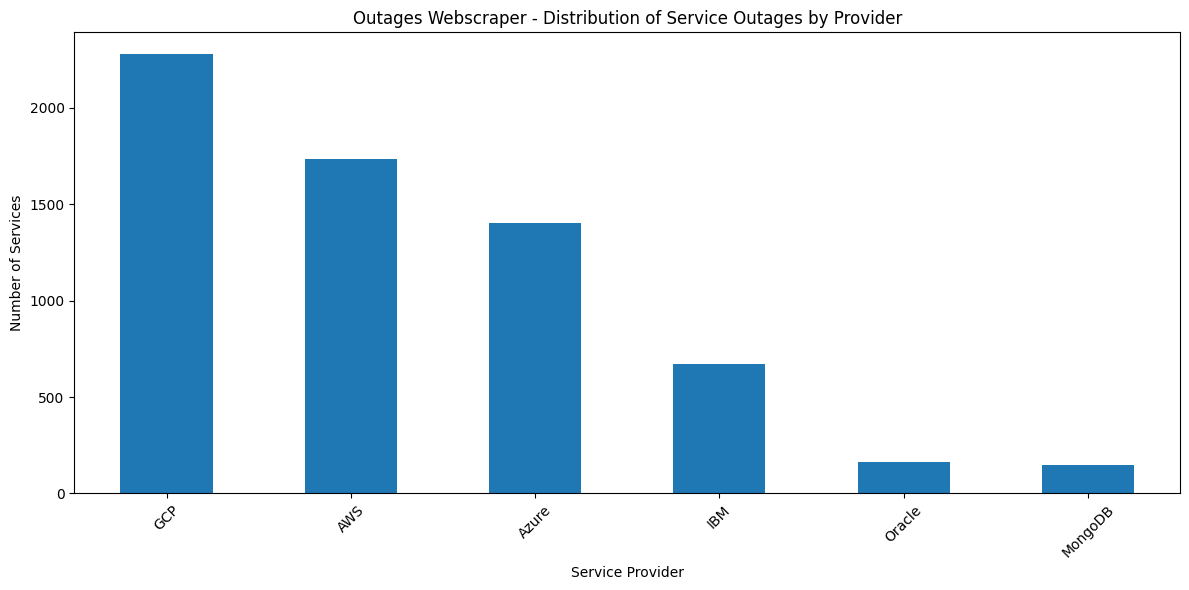

In [19]:
# 5. Outages Webscraper - Service Provider Distribution:
df = df_outages_dedup
plt.figure(figsize=(12, 6))
df['cloud_provider'].value_counts().plot(kind='bar')
plt.title('Outages Webscraper - Distribution of Service Outages by Provider')
plt.xlabel('Service Provider')
plt.ylabel('Number of Services')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
df_play.head(1)

,outage_timestamp,source_outage_report,cloud_provider,cloud_service,regions,availability_zones,start_time,end_time,outage_status,impact,duration,duration_minutes,root_cause,resolution,downtime_period,incident_id,affected_components,mitigation_steps,cloudrisk_genai_output
4854,1.699395e+09,outages_files/OCI Status - Outage Report - Tue...,Oracle,Network,mexico central (queretaro),not specified,2023-11-07T22:10:04+00:00,2023-11-07T22:57:40+00:00,resolved,NaN,391 days,563040,Not specified,NaN,Not specified,NaN,Oracle Cloud Infrastructure (OCI),NaN,Source Outage Report: outages_files/OCI Status...


In [21]:
df_play.tail(1)

,outage_timestamp,source_outage_report,cloud_provider,cloud_service,regions,availability_zones,start_time,end_time,outage_status,impact,duration,duration_minutes,root_cause,resolution,downtime_period,incident_id,affected_components,mitigation_steps,cloudrisk_genai_output
182,1.630568e+09,outages_files/20210913-Summary of AWS Direct C...,AWS,Amazon SageMaker,tokyo (ap-northeast-1),not specified,2021-09-02T07:30:00+00:00,2021-09-02T04:00:00+00:00,resolved,NaN,Start time: 2021-09-02 07:30:00 UTC,0,Failure of a subset of network devices on one ...,NaN,2021-09-02 07:30:00 UTC - 2021-09-02 12:30:00 ...,NaN,Amazon AWS Direct Connect,NaN,Source Outage Report: outages_files/20210913-S...


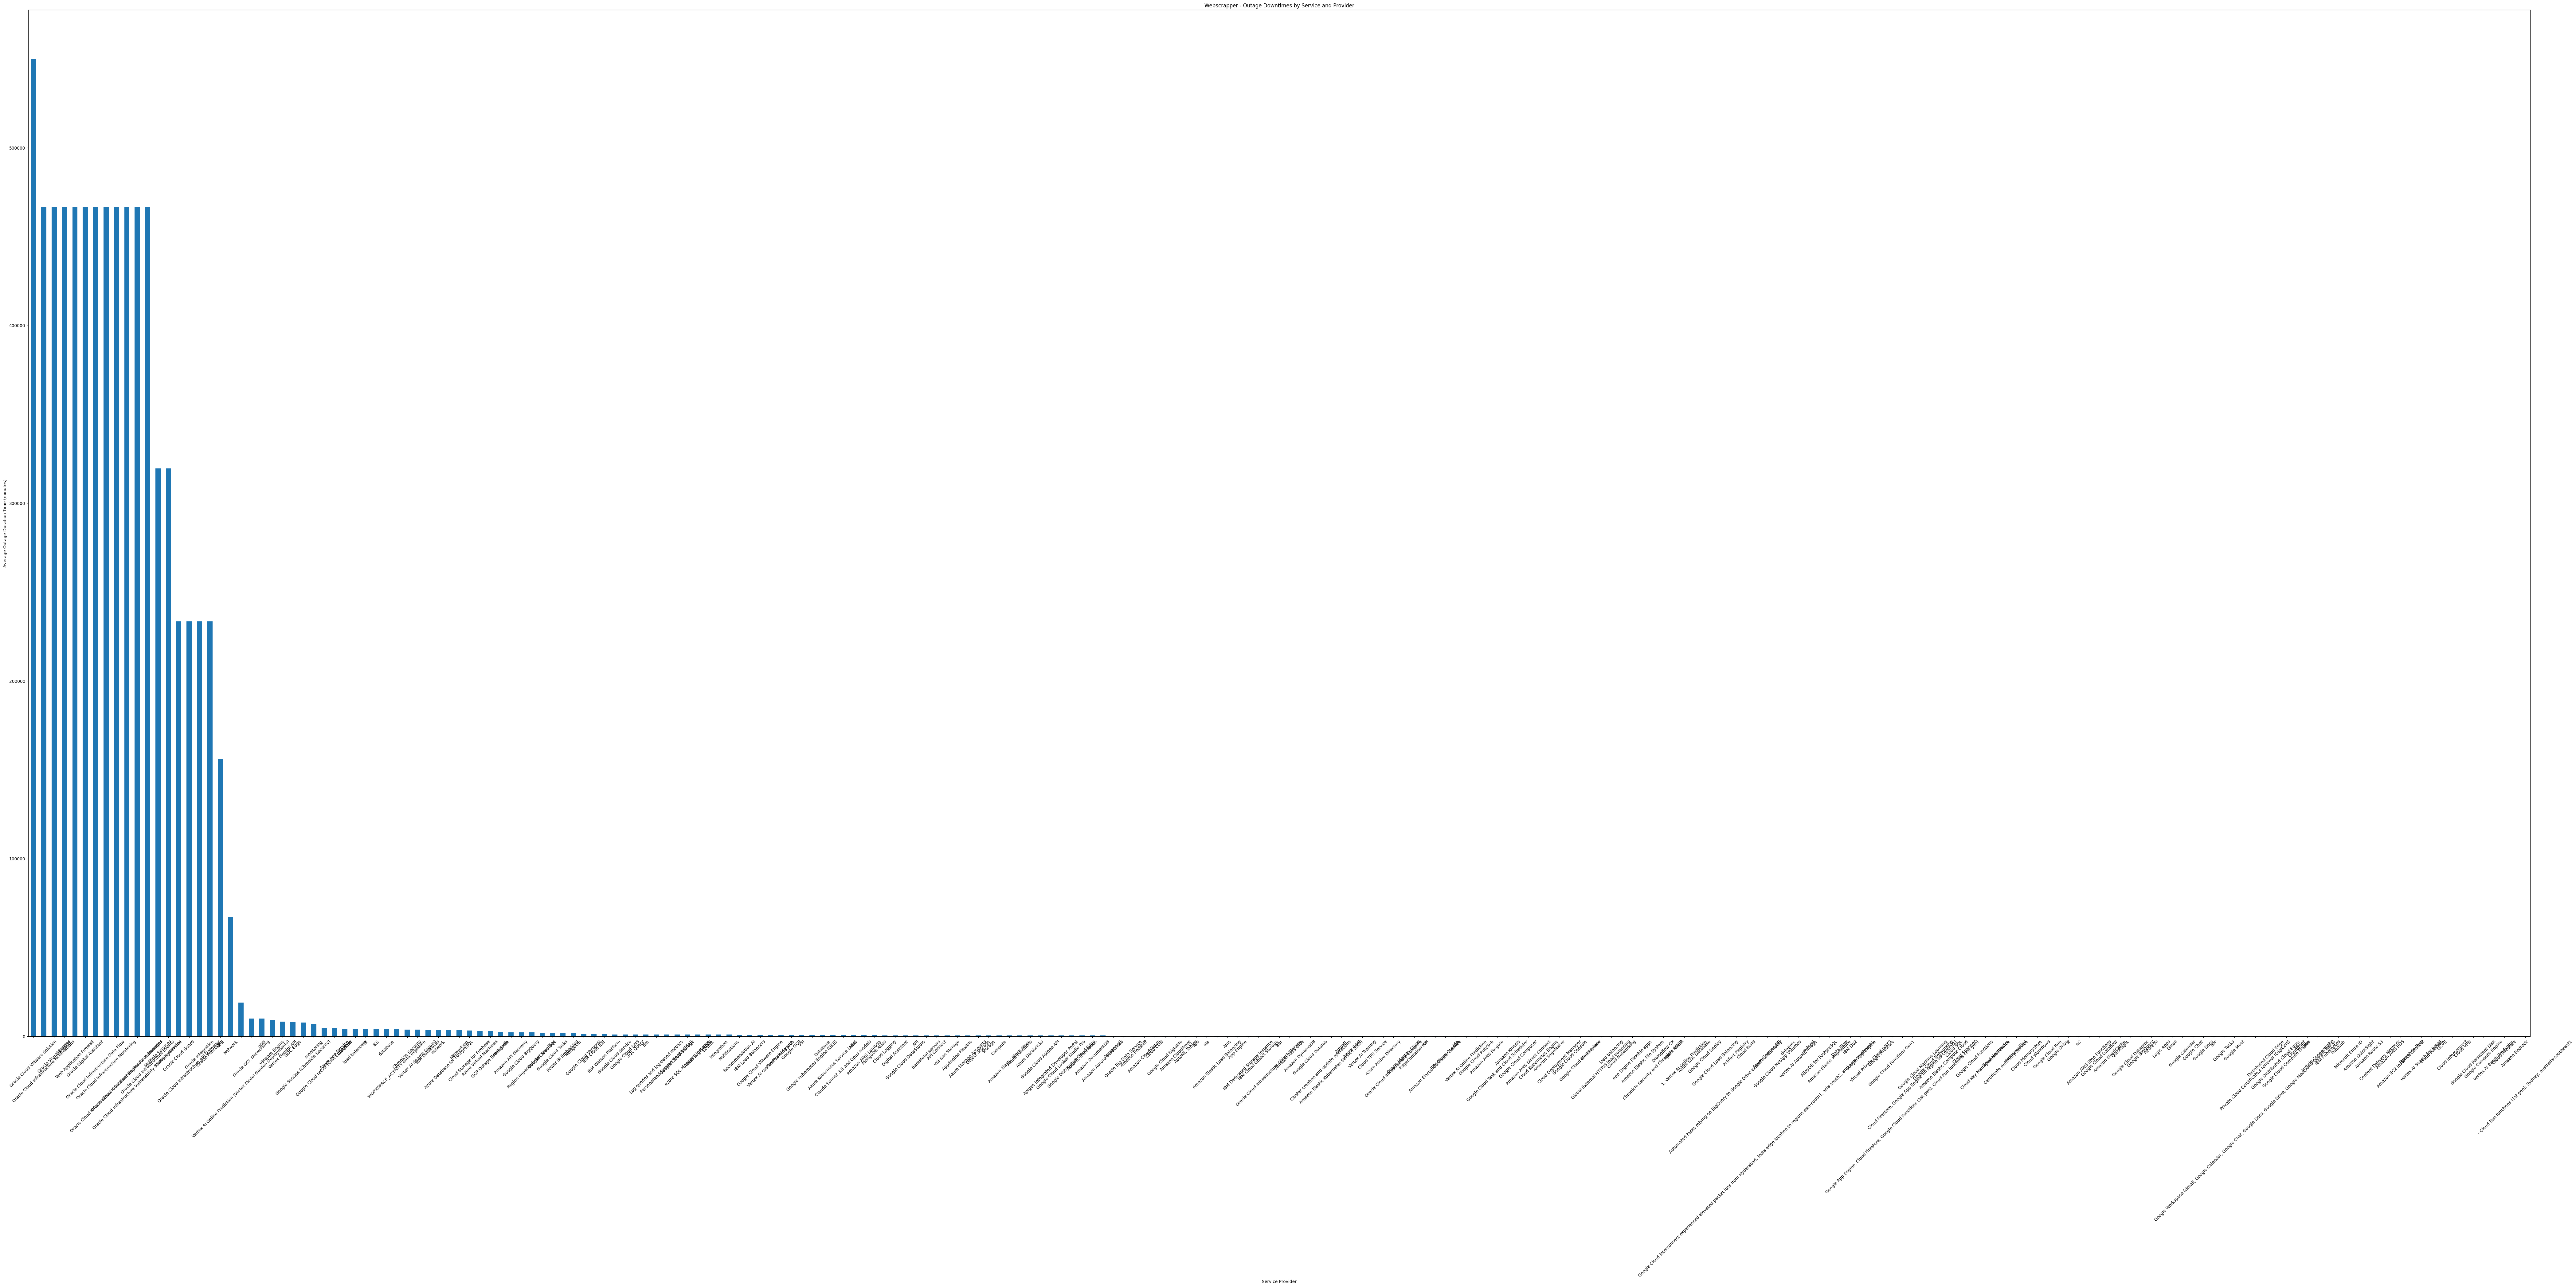

<Figure size 640x480 with 0 Axes>

In [22]:
# 6. Webscrapper - Outage Downtimes by Service and Provider:
plt.figure(figsize=(84, 42))
df.groupby('cloud_service')['duration_minutes'].mean().sort_values(ascending=False).plot(kind='bar')
plt.title('Webscrapper - Outage Downtimes by Service and Provider')
plt.xlabel('Service Provider')
plt.ylabel('Average Outage Duration Time (minutes)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
plt.savefig('Webscrapper_-_Outage_Downtimes_by_Service_and_Provider-plot.png',dpi=300)

In [23]:
print("done!")

done!


In [24]:
exit()